# Swin Transformer

In [2]:
#Mount Google Drive

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
#Import Libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

In [4]:
#Check GPU

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## 1.Dataset Setup

In [5]:
#Set the existing split dataset paths

split_dataset = "/content/drive/MyDrive/PCOS_Project/SPLIT_DATASET"

train_dir = os.path.join(split_dataset, "train")
test_dir = os.path.join(split_dataset, "test")

print("Train directory:", train_dir)
print("Test directory :", test_dir)

Train directory: /content/drive/MyDrive/PCOS_Project/SPLIT_DATASET/train
Test directory : /content/drive/MyDrive/PCOS_Project/SPLIT_DATASET/test


In [6]:
#Verify Folder Structure

print("Train classes:")
print(os.listdir(train_dir))

print("\nTest classes:")
print(os.listdir(test_dir))

Train classes:
['infected', 'noninfected']

Test classes:
['infected', 'noninfected']


## 2.Preprocessing and Augmentation

In [7]:
#Define transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=5, fill=0),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Transforms created successfully.")

Transforms created successfully.


## 3. Create Dataset and DataLoaders

In [8]:
#Load datasets

train_dataset = datasets.ImageFolder(
    root=train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    root=test_dir,
    transform=test_transform
)

print("Train samples:", len(train_dataset))
print("Test samples :", len(test_dataset))
print("Classes      :", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)

Train samples: 3142
Test samples : 786
Classes      : ['infected', 'noninfected']
Class mapping: {'infected': 0, 'noninfected': 1}


In [9]:
#Create DataLoaders

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Train batches:", len(train_loader))
print("Test batches :", len(test_loader))

Train batches: 99
Test batches : 25


In [10]:
#Final preprocessing verification

images, labels = next(iter(train_loader))

print("Final preprocessing verification")
print("-" * 40)
print("Batch shape :", images.shape)
print("Labels shape:", labels.shape)
print("Data type   :", images.dtype)
print("Labels      :", labels.unique().tolist())

Final preprocessing verification
----------------------------------------
Batch shape : torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Data type   : torch.float32
Labels      : [0, 1]


## 4.Load Swin Transformer

In [11]:
#Load pretrained Swin Transformer

swin_model = models.swin_t(
    weights=models.Swin_T_Weights.DEFAULT
)

print(swin_model.head)

Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:01<00:00, 67.9MB/s]


Linear(in_features=768, out_features=1000, bias=True)


In [12]:
#Replace the classification head for 2 classes

num_features = swin_model.head.in_features

swin_model.head = nn.Linear(num_features, 2)

swin_model = swin_model.to(device)

print(swin_model.head)
print("\nModel device:", next(swin_model.parameters()).device)

Linear(in_features=768, out_features=2, bias=True)

Model device: cuda:0


## 5.Loss Function and Optimizer

In [13]:
#Define loss function and optimizer

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    swin_model.parameters(),
    lr=0.0001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


## 6.Train Swin Transformer

In [14]:
#Train Swin Transformer

num_epochs = 5

train_losses = []
train_accuracies = []

for epoch in range(num_epochs):

    swin_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        #Forward pass
        outputs = swin_model(images)

        #Calculate loss
        loss = criterion(outputs, labels)

        #Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        #Calculate statistics
        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/5] Loss: 0.1388 Accuracy: 94.78%
Epoch [2/5] Loss: 0.0377 Accuracy: 99.01%
Epoch [3/5] Loss: 0.0385 Accuracy: 99.05%
Epoch [4/5] Loss: 0.0297 Accuracy: 99.30%
Epoch [5/5] Loss: 0.0280 Accuracy: 99.24%


In [15]:
#Save trained Swin Transformer

model_path = "/content/drive/MyDrive/PCOS_Project/swin_transformer.pth"

torch.save(swin_model.state_dict(), model_path)

print("Swin Transformer model saved successfully.")
print("Saved to:", model_path)

Swin Transformer model saved successfully.
Saved to: /content/drive/MyDrive/PCOS_Project/swin_transformer.pth


## 7.Evaluate Swin Transformer

In [16]:
#Evaluate Swin Transformer on the test dataset

swin_model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = swin_model(images)

        probabilities = torch.softmax(outputs, dim=1)
        _, predictions = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities[:, 1].cpu().numpy())

print("Evaluation completed successfully.")
print("Test samples evaluated:", len(all_labels))

Evaluation completed successfully.
Test samples evaluated: 786


## 8.Calculate Metrics


In [17]:
#Calculate Swin Transformer performance metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels,
    all_predictions,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    zero_division=0
)

roc_auc = roc_auc_score(
    all_labels,
    all_probabilities
)

print("Swin Transformer Test Results")
print("-" * 40)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Swin Transformer Test Results
----------------------------------------
Accuracy : 0.9885
Precision: 0.9804
Recall   : 0.9615
F1-score : 0.9709
ROC-AUC  : 0.9974


## 9.Classification Report

In [18]:
#Generate classification report

print("Swin Transformer Classification Report")
print("-" * 50)

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["infected", "noninfected"],
        digits=2
    )
)

Swin Transformer Classification Report
--------------------------------------------------
              precision    recall  f1-score   support

    infected       0.99      1.00      0.99       630
 noninfected       0.98      0.96      0.97       156

    accuracy                           0.99       786
   macro avg       0.99      0.98      0.98       786
weighted avg       0.99      0.99      0.99       786



## 10.Confusion Matrix

Swin Transformer Confusion Matrix
----------------------------------------
[[627   3]
 [  6 150]]


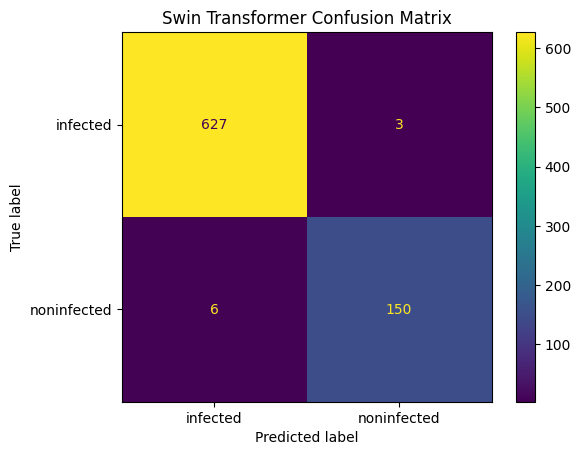


Confusion matrix saved to:
/content/drive/MyDrive/PCOS_Project/swin_confusion_matrix.png


In [21]:
#Generate and save confusion matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("Swin Transformer Confusion Matrix")
print("-" * 40)
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["infected", "noninfected"]
)

disp.plot()

plt.title("Swin Transformer Confusion Matrix")

#Save figure
cm_path = "/content/drive/MyDrive/PCOS_Project/swin_confusion_matrix.png"

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nConfusion matrix saved to:")
print(cm_path)

## 11.ROC Curve

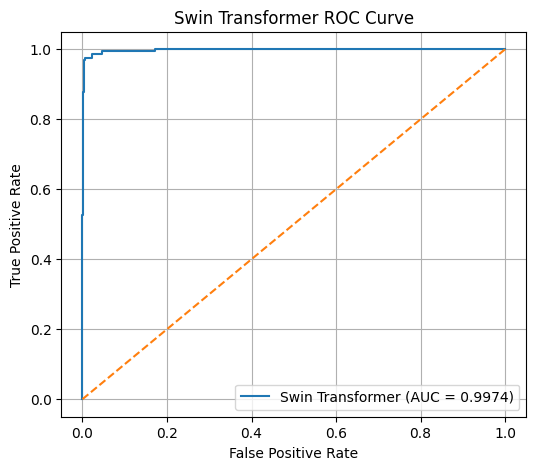


ROC curve saved to:
/content/drive/MyDrive/PCOS_Project/swin_roc_curve.png


In [22]:
#Plot and save ROC curve

from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(
    all_labels,
    all_probabilities
)

roc_auc_value = auc(fpr, tpr)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Swin Transformer (AUC = {roc_auc_value:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Swin Transformer ROC Curve")
plt.legend(loc="lower right")
plt.grid()

#Save figure
roc_path = "/content/drive/MyDrive/PCOS_Project/swin_roc_curve.png"

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nROC curve saved to:")
print(roc_path)

## 12.Save Swin Transformer Results

In [27]:
#Save Swin Transformer results to CSV

results = {
    "Model": "Swin Transformer",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "ROC-AUC": roc_auc
}

results_df = pd.DataFrame([results])

results_path = "/content/drive/MyDrive/PCOS_Project/swin_transformer_results.csv"

results_df.to_csv(
    results_path,
    index=False
)

print("Swin Transformer results saved successfully.")
print("Saved to:", results_path)

display(results_df)

Swin Transformer results saved successfully.
Saved to: /content/drive/MyDrive/PCOS_Project/swin_transformer_results.csv


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Swin Transformer,0.98855,0.980392,0.961538,0.970874,0.997405


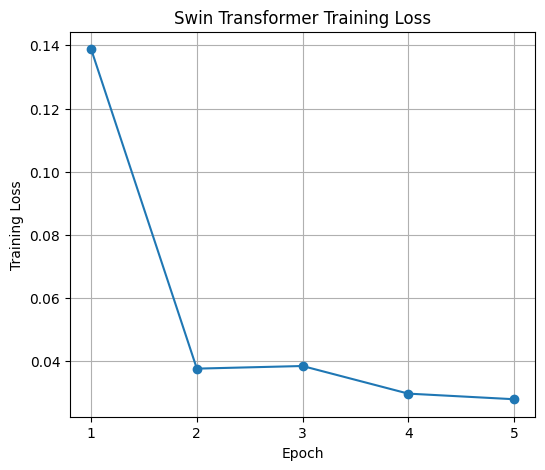

Training loss figure saved to:
/content/drive/MyDrive/PCOS_Project/swin_training_loss.png


In [23]:
#Plot and save training loss

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(6, 5))

plt.plot(
    epochs,
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Swin Transformer Training Loss")
plt.xticks(epochs)
plt.grid()

loss_path = "/content/drive/MyDrive/PCOS_Project/swin_training_loss.png"

plt.savefig(
    loss_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Training loss figure saved to:")
print(loss_path)

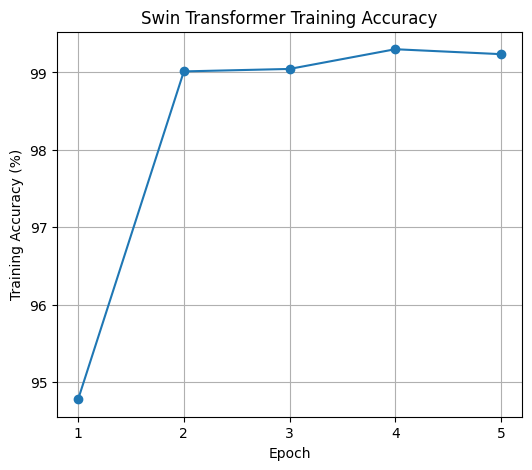

Training accuracy figure saved to:
/content/drive/MyDrive/PCOS_Project/swin_training_accuracy.png


In [24]:
#Plot and save training accuracy

plt.figure(figsize=(6, 5))

plt.plot(
    epochs,
    train_accuracies,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.title("Swin Transformer Training Accuracy")
plt.xticks(epochs)
plt.grid()

accuracy_path = "/content/drive/MyDrive/PCOS_Project/swin_training_accuracy.png"

plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Training accuracy figure saved to:")
print(accuracy_path)